# PRCP-1000 · Portuguese Bank — Term Deposit Subscription Prediction

**Domain:** Finance / Banking  **Data:** `bank-additional-full.csv` (direct phone-call marketing campaigns, May 2008 – November 2010)

| Deliverable | Section |
|---|---|
| Task 1 – complete data analysis report | 2 – 4 |
| Task 2 – predictive model: which customer will buy | 5 – 11 |
| Task 3 – suggestions to the bank marketing team | 13 |
| Model comparison report + best model for production | 7, 12 |
| Report on challenges faced (technique + reason) | 14 |

## Design of this notebook (and why)
1. **Split first, explore after.** The data are split into **train 60 % / validation 20 % / test 20 %** (stratified) *before* any exploration. EDA, feature decisions and every fitted step use the training part only.
2. **Strict roles for each part.** Train → model comparison and tuning (cross-validation inside it). **Validation → decision threshold, calibration and feature importance.** **Test → touched once**, for the final report. No decision uses the test set.
3. **One `Pipeline`** holds every fitted step, so nothing leaks. Only stateless, row-wise feature construction happens outside fitted steps.
4. **Excluded inputs:** `duration` (known only after the call) and `campaign` (it counts the final call that produced the outcome, so the total is not known before calling).
5. **Comparable tuning for every serious model** (same folds, metric and search budget); the final model is picked by a rule fixed in advance and then used everywhere.
6. **Time is a threat to validity.** The file is chronological and conversion rates change from ≈ 5 % (2008) to ≈ 52 % (2010). A random split mixes periods and is therefore optimistic. Section 11 is a dedicated **temporal stress test** (chronological hold-out and rolling windows) that quantifies this, and the conclusions are written accordingly.
7. **Uncertainty is reported:** bootstrap confidence intervals, calibration, subgroup errors.


**Requirements:** Python ≥ 3.8, `pandas`, `numpy`, `scipy`, `scikit-learn` (≥ 1.0), `xgboost`, `matplotlib`, `seaborn`. Put `bank-additional-full.csv` next to the notebook (or in `Data/bank-additional/`). Run top to bottom (≈ 6–8 minutes on one CPU); results are reproducible (`random_state = 42`).


In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silences a harmless joblib core-count warning on some Windows PCs
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import loguniform, uniform

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score, accuracy_score, brier_score_loss,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
RS = 42
pd.set_option("display.max_columns", 50, "display.width", 170)

## 1. Load the data

In [2]:
CANDIDATES = [r"C:\Users\rupab\OneDrive\Desktop\PortugeseBank\bank-additional-full.csv",
              "bank-additional-full.csv", "Data/bank-additional/bank-additional-full.csv"]
PATH = next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])
raw = pd.read_csv(PATH, sep=";")
print("File:", PATH, "| shape:", raw.shape)
raw.head()

File: C:\Users\rupab\OneDrive\Desktop\PortugeseBank\bank-additional-full.csv | shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data understanding (Task 1 – part A)

### 2.1 Structure and data types

In [3]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "n_NaN": raw.isna().sum(),
                     "n_'unknown'": (raw == "unknown").sum()})
display(info)

,dtype,n_unique,n_NaN,n_'unknown'
age,int64,78,0,0
job,object,12,0,330
marital,object,4,0,80
education,object,8,0,1731
default,object,3,0,8597
housing,object,3,0,990
loan,object,3,0,990
contact,object,2,0,0
month,object,10,0,0
day_of_week,object,5,0,0


### 2.2 Missing information: real `NaN`s vs. `unknown`
In the Ames data, missing values were *structural* (no pool → `NA`). Here there are no `NaN`s at all; missing information is stored as the text **`unknown`**. For every affected column the table below shows how many rows are affected and whether "unknown" behaves differently from known values.

In [4]:
rows = []
for c in [c for c in raw.columns if (raw[c] == "unknown").any()]:
    m = raw[c] == "unknown"
    rows.append({"column": c, "n_unknown": int(m.sum()), "pct_unknown": round(100 * m.mean(), 2),
                 "rate_if_unknown": round((raw.loc[m, "y"] == "yes").mean(), 3),
                 "rate_if_known": round((raw.loc[~m, "y"] == "yes").mean(), 3)})
display(pd.DataFrame(rows).set_index("column"))
print("housing and loan are 'unknown' on exactly the same rows:", bool(((raw.housing == "unknown") == (raw.loan == "unknown")).all()))
print("Rows with at least one 'unknown':", int((raw == "unknown").any(axis=1).sum()))

,n_unknown,pct_unknown,rate_if_unknown,rate_if_known
column,,,,
job,330,0.80,0.112,0.113
marital,80,0.19,0.150,0.113
education,1731,4.20,0.145,0.111
default,8597,20.87,0.052,0.129
housing,990,2.40,0.108,0.113
loan,990,2.40,0.108,0.113


housing and loan are 'unknown' on exactly the same rows: True
Rows with at least one 'unknown': 10700


**Decision:** `unknown` is a *genuinely unknown* value (the bank has no record), not a structurally absent feature, so it is **kept as its own category** instead of being imputed. Imputing e.g. 21 % of `default` would invent information, and "unknown" is itself predictive (see the rates above).

### 2.3 Duplicate rows – evidence before removal

In [5]:
dups = raw[raw.duplicated(keep=False)].copy()
dups["row_pos"] = dups.index
display(dups.sort_values(list(raw.columns))[["row_pos", "age", "job", "education", "duration", "campaign", "month", "day_of_week", "euribor3m", "y"]])
gap = dups.groupby(list(raw.columns))["row_pos"].agg(lambda s: s.max() - s.min())
print(f"{raw.duplicated().sum()} duplicate rows ({100 * raw.duplicated().mean():.3f} % of the data); largest distance between a row and its copy: {gap.max()} rows")

,row_pos,age,job,education,duration,campaign,month,day_of_week,euribor3m,y
28476,28476,24,services,high.school,114,1,apr,tue,1.423,no
28477,28477,24,services,high.school,114,1,apr,tue,1.423,no
14155,14155,27,technician,professional.course,331,2,jul,mon,4.962,no
14234,14234,27,technician,professional.course,331,2,jul,mon,4.962,no
18464,18464,32,technician,professional.course,128,1,jul,thu,4.968,no
18465,18465,32,technician,professional.course,128,1,jul,thu,4.968,no
32505,32505,35,admin.,university.degree,348,4,may,fri,1.313,no
32516,32516,35,admin.,university.degree,348,4,may,fri,1.313,no
12260,12260,36,retired,unknown,88,1,jul,thu,4.966,no
12261,12261,36,retired,unknown,88,1,jul,thu,4.966,no


12 duplicate rows (0.029 % of the data); largest distance between a row and its copy: 144 rows


**Justification for removal:** each pair agrees on **all 21 columns**, including the call length to the second and the 3-decimal Euribor value, and the copies sit close together in the file (consistent with double entry). Two different calls matching on every field would be extremely unlikely. They are removed (the removal is row-wise and learns nothing from the data, so doing it before the split cannot leak). With only 0.03 % of the rows involved, the choice cannot materially change any result.

In [6]:
df = raw.drop_duplicates().reset_index(drop=True)
df["target"] = (df["y"] == "yes").astype(int)
print("After de-duplication:", df.shape, "| positive rate:", round(df["target"].mean(), 4))

After de-duplication: (41176, 22) | positive rate: 0.1127


### 2.4 Is the file really chronological?
The dataset documentation says the rows are ordered by date. This is verified rather than assumed: the months must form a continuous May 2008 → Nov 2010 sequence, and the (daily) Euribor rate should trend smoothly with row position.

Order of months as they appear in the file:
 may → jun → jul → aug → oct → nov → dec → mar → apr → may → jun → jul → aug → sep → oct → nov → dec → mar → apr → may → jun → jul → aug → sep → oct → nov

Number of calendar wraps found: 2 (expected 2 for 2008 -> 2010)


,calls,subscription_rate,mean_euribor3m,first_month,last_month
year_proxy,,,,,
2008,27682,0.048,4.817,may,dec
2009,11436,0.195,1.232,mar,dec
2010,2058,0.521,0.813,mar,nov


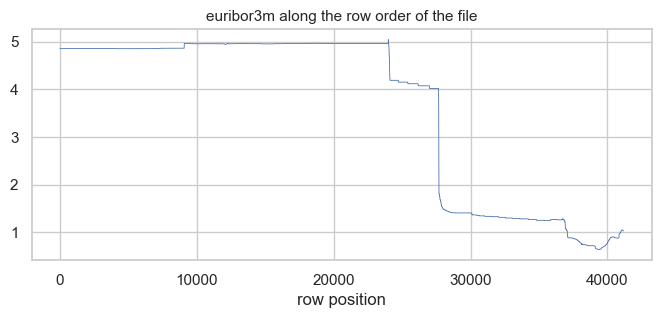

In [7]:
runs, prev = [], None
for m in raw.month:
    if m != prev: runs.append(m); prev = m
print("Order of months as they appear in the file:\n", " → ".join(runs))
month_num = df["month"].map({"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6, "jul": 7,
                             "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12})
df["year_proxy"] = 2008 + (month_num.diff().fillna(0) < 0).cumsum()      # +1 each time the month number wraps (Dec -> Mar)
print("\nNumber of calendar wraps found:", int((month_num.diff().fillna(0) < 0).sum()), "(expected 2 for 2008 -> 2010)")
display(df.groupby("year_proxy").agg(calls=("target", "size"), subscription_rate=("target", "mean"),
                                    mean_euribor3m=("euribor3m", "mean"), first_month=("month", "first"),
                                    last_month=("month", "last")).round(3))
fig, ax = plt.subplots(figsize=(8, 3)); ax.plot(df.index, df["euribor3m"], lw=.6)
ax.set_title("euribor3m along the row order of the file"); ax.set_xlabel("row position"); plt.show()

**Result:** the months run May–Dec 2008, Mar–Dec 2009 and Mar–Nov 2010 with exactly two calendar wraps, and `euribor3m` falls smoothly from about 5 % to below 1 % along the file. The file is therefore chronological, and the row position (and the derived `year_proxy`, used only for exploration and reporting – **never as a model input**) is a valid time axis.

### 2.5 Train / validation / test split — *before* any exploration

In [8]:
FEATURES = [c for c in df.columns if c not in ("y", "target", "year_proxy")]
X_all, y_all = df[FEATURES], df["target"]
X_tmp, X_test, y_tmp, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=RS)
X_fit, X_val, y_fit, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RS)
split_tbl = pd.DataFrame({"rows": [len(X_fit), len(X_val), len(X_test)],
                          "positive rate": [y_fit.mean(), y_val.mean(), y_test.mean()],
                          "used for": ["EDA, model comparison, tuning (cross-validation)",
                                       "decision threshold, calibration, feature importance",
                                       "final report ONLY (touched once)"]}, index=["train (60 %)", "validation (20 %)", "test (20 %)"])
display(split_tbl.round(4))
eda = X_fit.copy(); eda["target"] = y_fit; eda["year_proxy"] = df.loc[X_fit.index, "year_proxy"]
num_cols = [c for c in eda.select_dtypes("number").columns if c not in ("target", "year_proxy")]
cat_cols = [c for c in eda.columns if c not in num_cols + ["target", "year_proxy"]]
print("numeric:", num_cols); print("categorical:", cat_cols)

,rows,positive rate,used for
train (60 %),24705,0.1126,"EDA, model comparison, tuning (cross-validation)"
validation (20 %),8235,0.1127,"decision threshold, calibration, feature impor..."
test (20 %),8236,0.1127,final report ONLY (touched once)


numeric: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### 2.7 Descriptive statistics (train)

In [9]:
display(eda[num_cols].describe().T.assign(skew=eda[num_cols].skew()).round(2))
display(eda[cat_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max,skew
age,24705.0,40.02,10.46,17.00,32.00,38.00,47.00,98.00,0.80
duration,24705.0,257.53,257.63,0.00,102.00,178.00,319.00,4199.00,3.19
campaign,24705.0,2.56,2.77,1.00,1.00,2.00,3.00,56.00,5.02
pdays,24705.0,962.75,186.22,0.00,999.00,999.00,999.00,999.00,-4.94
previous,24705.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00,3.91
emp.var.rate,24705.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40,-0.73
cons.price.idx,24705.0,93.57,0.58,92.20,93.08,93.75,93.99,94.77,-0.24
cons.conf.idx,24705.0,-40.49,4.63,-50.80,-42.70,-41.80,-36.40,-26.90,0.31
euribor3m,24705.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04,-0.71
nr.employed,24705.0,5167.16,72.20,4963.60,5099.10,5191.00,5228.10,5228.10,-1.04


,count,unique,top,freq
job,24705,12,admin.,6189
marital,24705,4,married,14942
education,24705,8,university.degree,7302
default,24705,3,no,19570
housing,24705,3,yes,12961
loan,24705,3,no,20320
contact,24705,2,cellular,15693
month,24705,10,may,8242
day_of_week,24705,5,thu,5167
poutcome,24705,3,nonexistent,21400


## 3. Univariate analysis (Task 1 – part B)

### 3.1 Target distribution

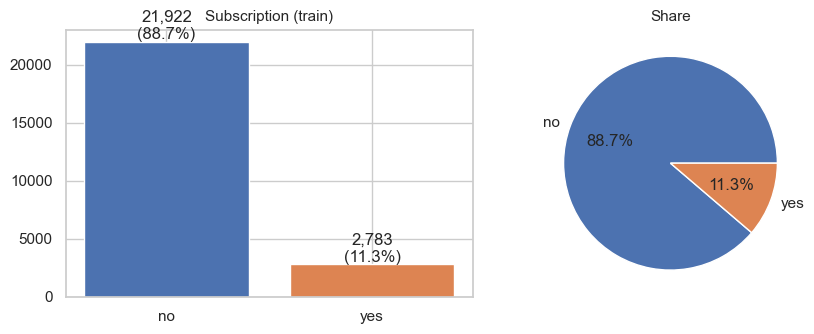

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
vc = eda["target"].map({0: "no", 1: "yes"}).value_counts()
ax[0].bar(vc.index, vc.values, color=["#4c72b0", "#dd8452"]); ax[0].set_title("Subscription (train)")
for i, v in enumerate(vc.values): ax[0].text(i, v, f"{v:,}\n({v / len(eda):.1%})", ha="center", va="bottom")
ax[1].pie(vc.values, labels=vc.index, autopct="%1.1f%%", colors=["#4c72b0", "#dd8452"]); ax[1].set_title("Share")
plt.tight_layout(); plt.show()

**Observation:** only **11.26 %** of the training customers subscribed (2,783 of 24,705); the imbalance ratio is ≈ 7.9 : 1. A model answering "no" for everyone would be 88.7 % accurate and useless, so accuracy is not used as the main metric (see Sections 6 and 9).

### 3.2 Every numeric feature: distribution and relationship with the target

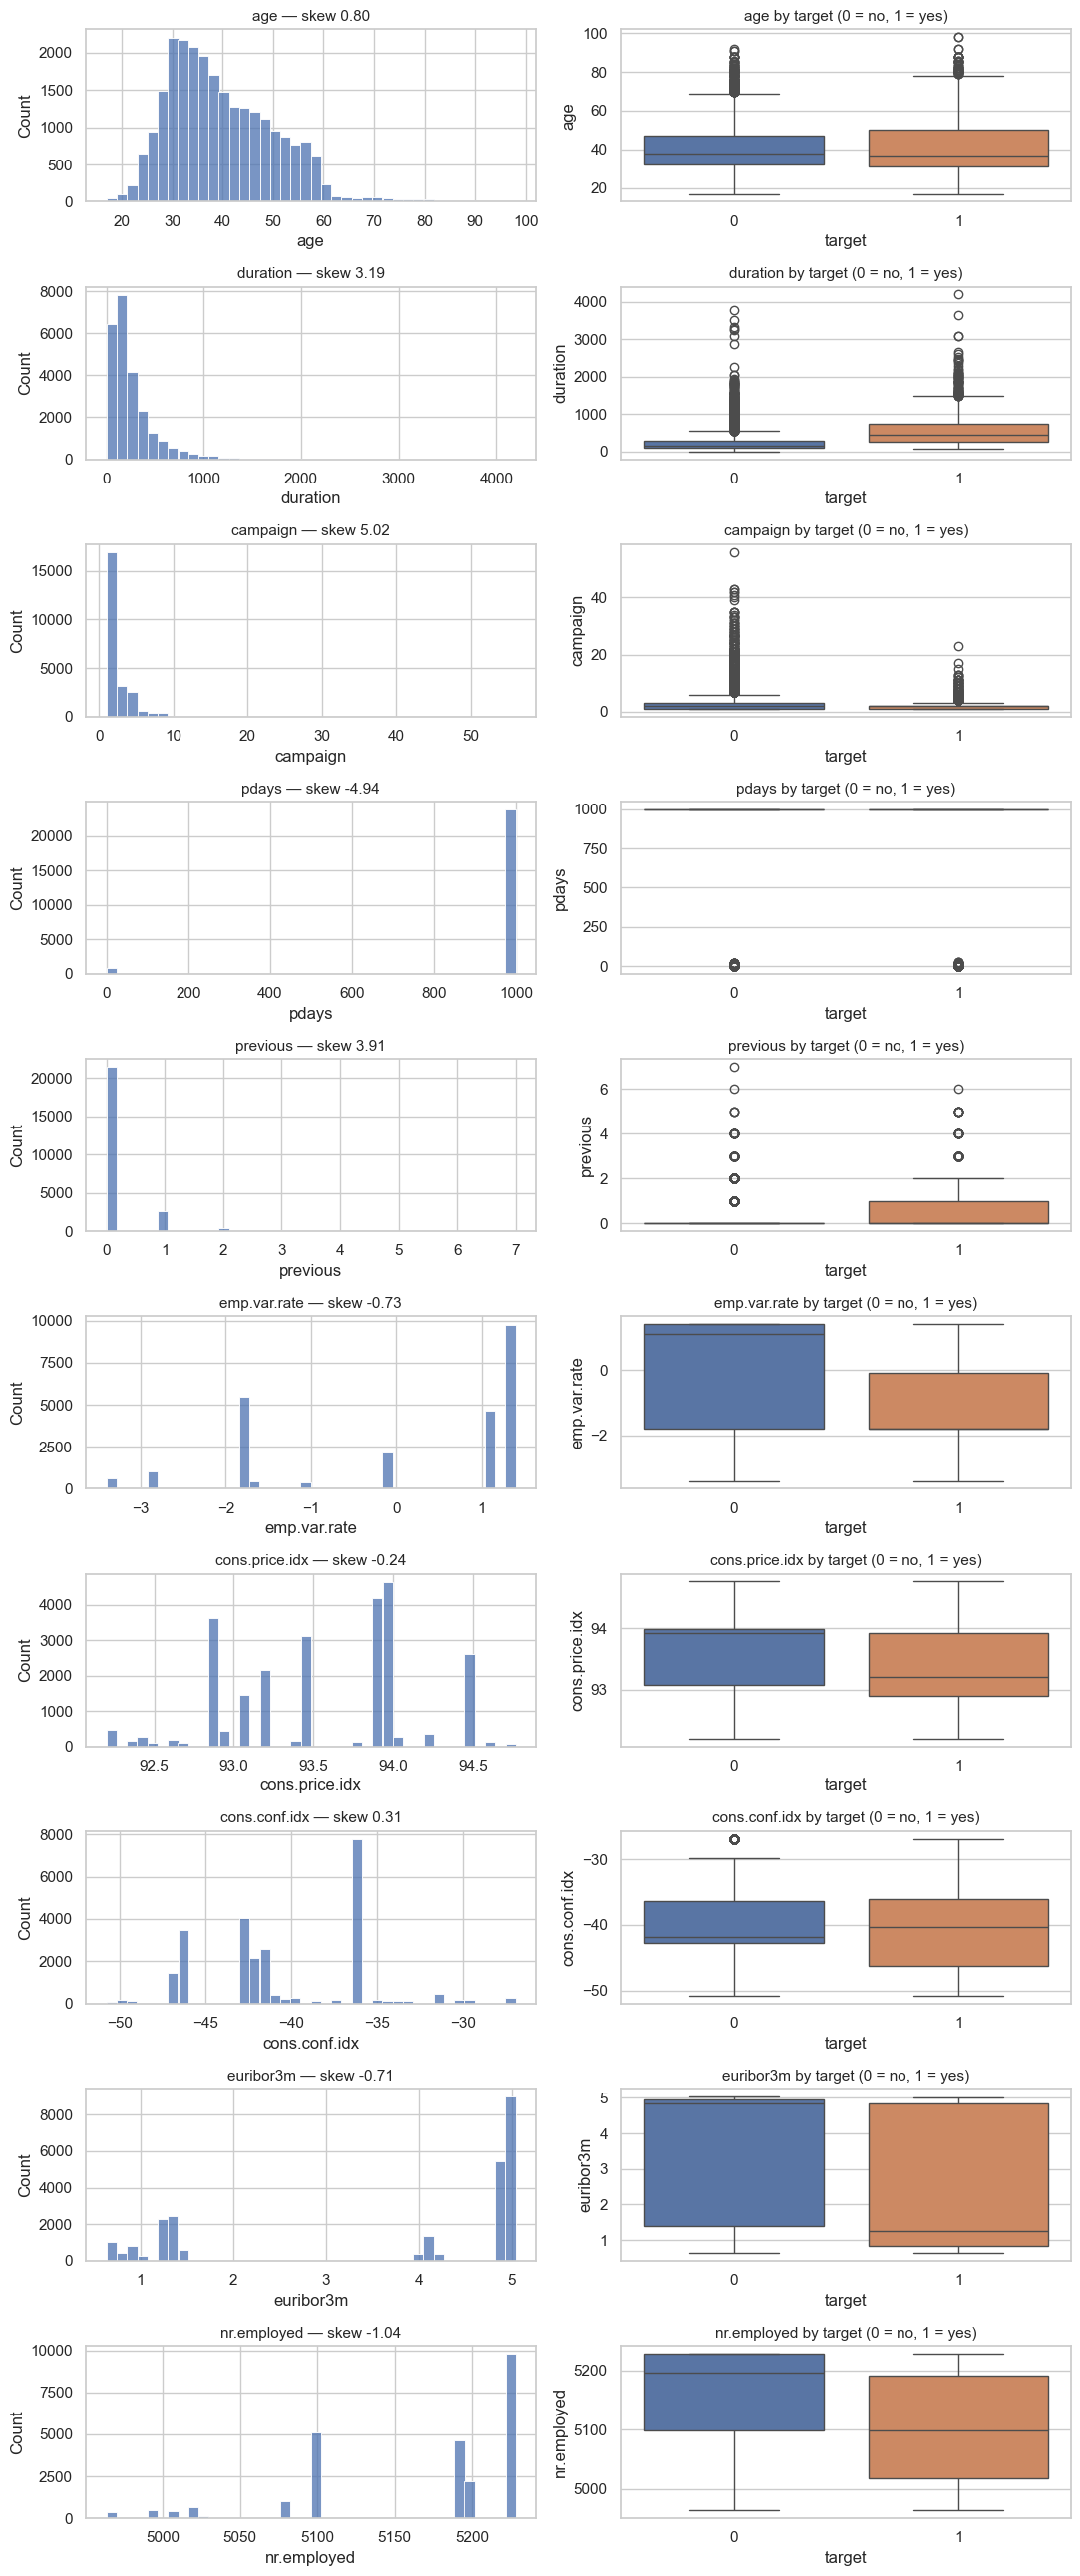

In [11]:
fig, axes = plt.subplots(len(num_cols), 2, figsize=(11, 2.6 * len(num_cols)))
for i, c in enumerate(num_cols):
    sns.histplot(eda[c], bins=40, ax=axes[i, 0], color="#4c72b0"); axes[i, 0].set_title(f"{c} — skew {eda[c].skew():.2f}")
    sns.boxplot(data=eda, x="target", y=c, ax=axes[i, 1], palette=["#4c72b0", "#dd8452"]); axes[i, 1].set_title(f"{c} by target (0 = no, 1 = yes)")
plt.tight_layout(); plt.show()

**Observations**
- `duration` (skew 3.2), `campaign` (5.0) and `previous` (3.9) are strongly right-skewed; `pdays` is dominated by the code 999 (96.3 % of customers never contacted before). `age` is unimodal (mean 40, max 98).
- Subscribers have **much longer calls** (leakage variable, excluded later) and **fewer contacts** in the campaign.
- The economic variables (`emp.var.rate`, `euribor3m`, `nr.employed`, `cons.price.idx`) are multimodal because they are *period* indicators: customers called in the same period share the same value. Subscribers concentrate in the low-rate / low-employment-variation periods.

### 3.3 Every categorical feature: cardinality and subscription rate

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
n_categories,12,4,8,3,3,3,2,10,5,3


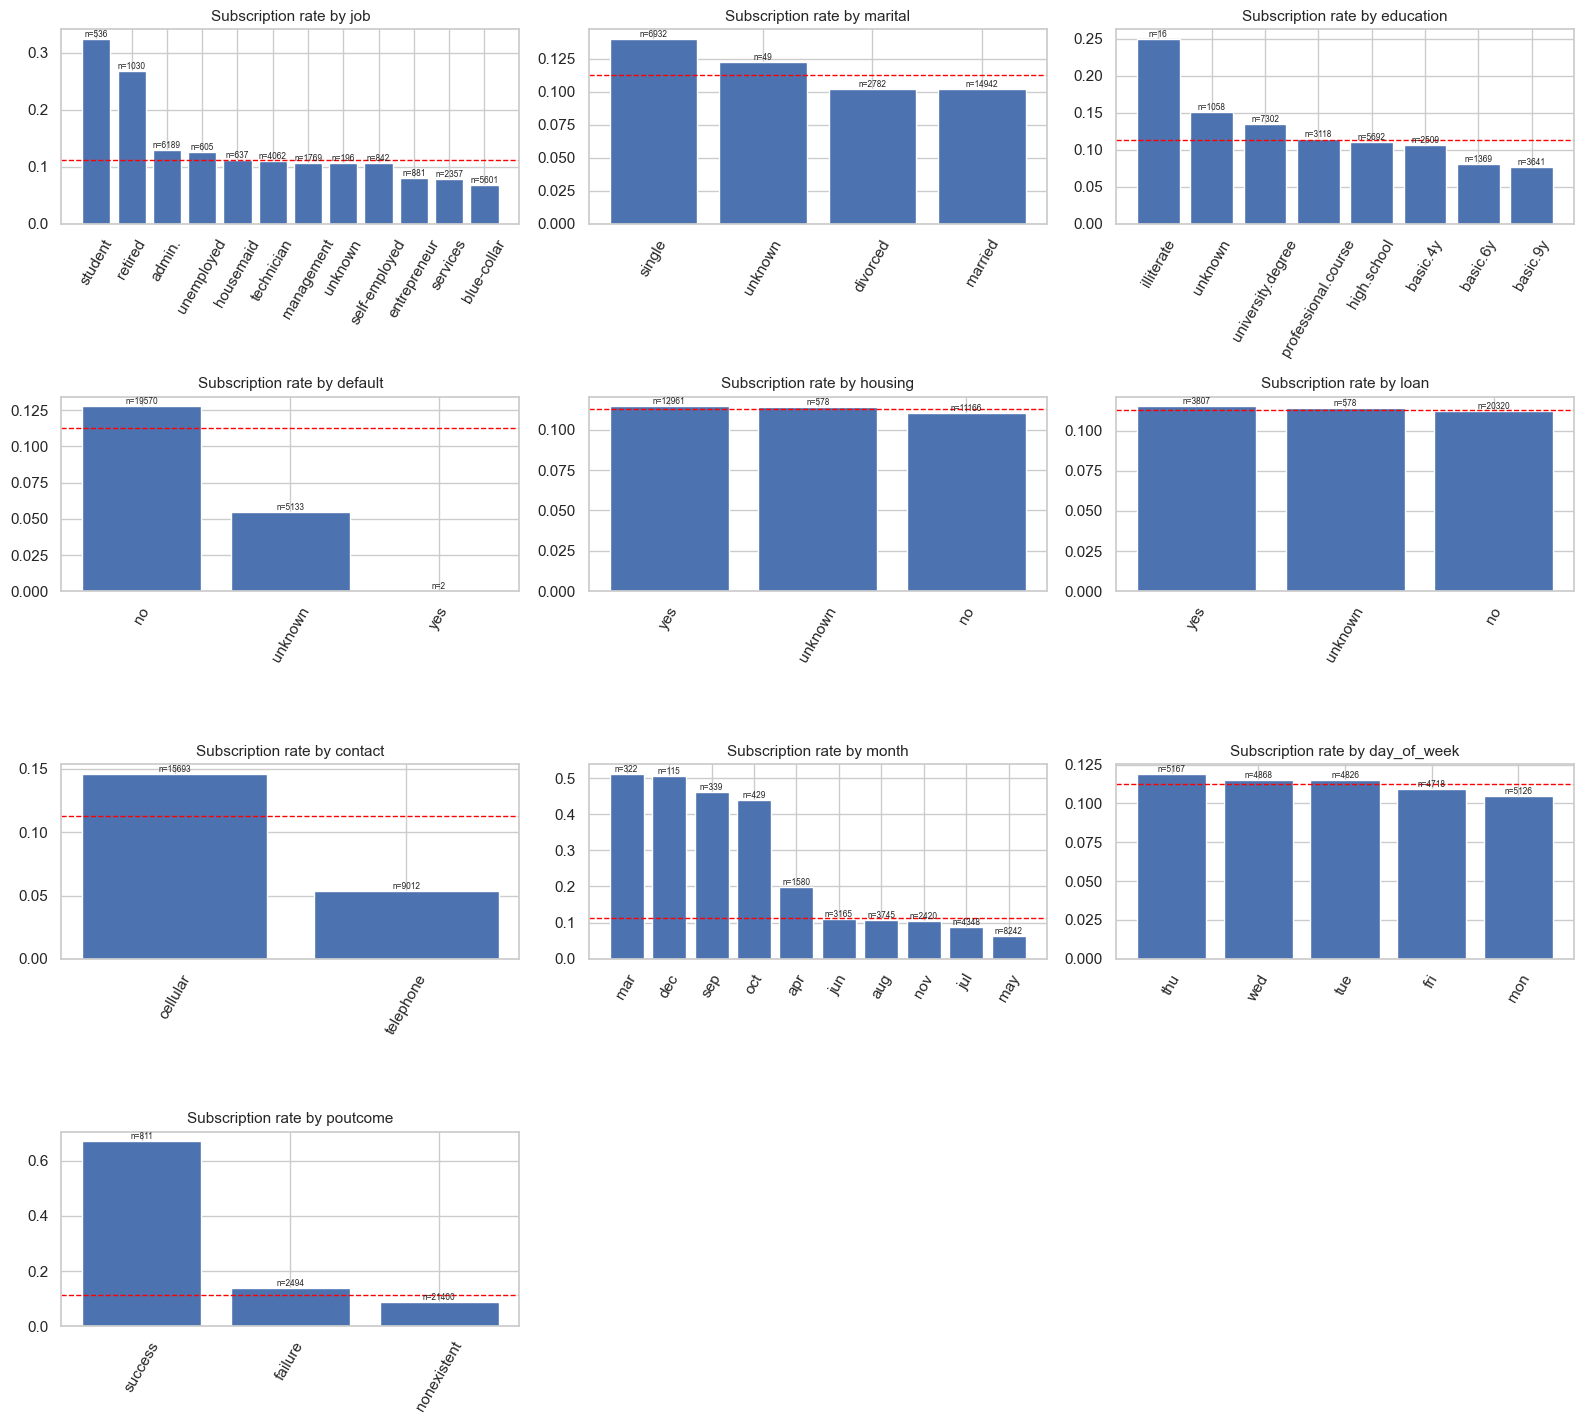

In [12]:
display(eda[cat_cols].nunique().rename("n_categories").to_frame().T)
n = len(cat_cols); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.6 * nrow)); axes = axes.ravel()
base = eda["target"].mean()
for ax, c in zip(axes, cat_cols):
    g = eda.groupby(c)["target"].agg(rate="mean", n="size").sort_values("rate", ascending=False)
    ax.bar(g.index, g["rate"], color="#4c72b0"); ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_title(f"Subscription rate by {c}"); ax.tick_params(axis="x", rotation=60)
    for t, (r, k) in enumerate(zip(g["rate"], g["n"])): ax.text(t, r, f"n={k}", ha="center", va="bottom", fontsize=6)
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

**Observations (red dashed line = overall rate 11.3 %)**
- **`poutcome = success` → 67.1 %** (vs 8.8 % when there was no previous campaign and 14.0 % after a failure).
- **`contact`:** cellular 14.6 % vs telephone 5.4 %.
- **`month`:** May holds **33 % of all calls at only 6.2 %**; March, September, October and December convert at 44 – 51 % but make up only ≈ 5 % of calls.
- **`job`:** students (32.5 %) and retired (26.7 %) lead; blue-collar (6.8 %) and services (7.9 %) are lowest. `marital`: single 14.0 % vs married/divorced 10.2 %.
- **`default`:** known "no" 12.8 % vs `unknown` 5.5 % (only 2 customers have `yes`). `housing`, `loan` (11.0 – 11.5 %) and `day_of_week` (10.5 – 11.9 %) are almost flat, i.e. weak individual predictors.
- All categorical variables have ≤ 12 levels, so one-hot encoding is safe; no high-cardinality treatment is needed.

## 4. Bi/multivariate analysis and data-quality checks (Task 1 – part C)

### 4.1 Correlation structure

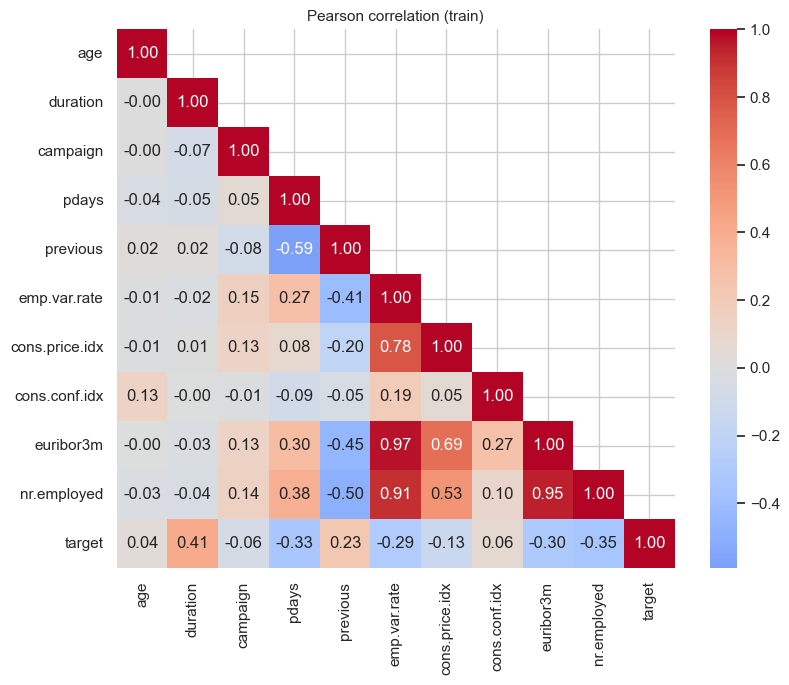

,corr with target
nr.employed,-0.348
pdays,-0.331
euribor3m,-0.301
emp.var.rate,-0.292
cons.price.idx,-0.134
campaign,-0.064
age,0.037
cons.conf.idx,0.063
previous,0.228
duration,0.410


In [13]:
corr = eda[num_cols + ["target"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, bool), 1))
plt.title("Pearson correlation (train)"); plt.show()
display(corr["target"].drop("target").sort_values().round(3).to_frame("corr with target"))

**Observations**
- Strongest linear correlations with the target: `duration` +0.41 (leakage), `nr.employed` −0.35, `pdays` −0.33, `euribor3m` −0.30, `emp.var.rate` −0.29, `previous` +0.23.
- The economic variables are **very highly inter-correlated** (above 0.9 for `emp.var.rate`/`euribor3m`/`nr.employed`); they carry largely the same "economic regime" information (quantified with VIF in Section 5.1).
- **Limits of this view:** Pearson correlation measures only *linear* association between numeric variables. It cannot see categorical effects (`month`, `poutcome`, `job`) or non-linear effects (the U-shaped age pattern below), so feature importance is re-examined with a model-based method in Section 10.2.

### 4.2 Age, contacts and previous contact

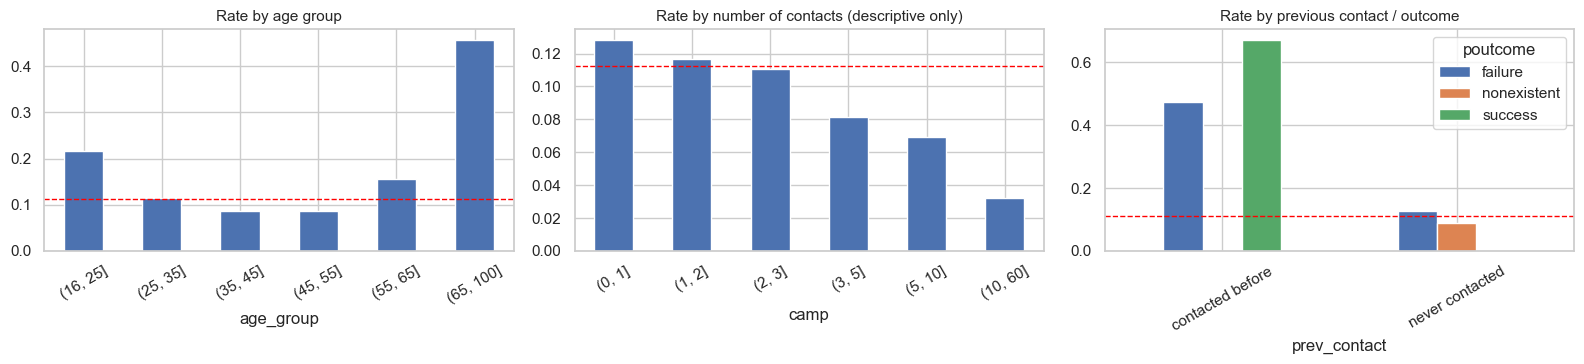

Share of customers never contacted before: 0.963


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
t = eda.assign(age_group=pd.cut(eda.age, [16, 25, 35, 45, 55, 65, 100]))
t.groupby("age_group", observed=True)["target"].mean().plot.bar(ax=ax[0], color="#4c72b0"); ax[0].set_title("Rate by age group")
t = eda.assign(camp=pd.cut(eda.campaign, [0, 1, 2, 3, 5, 10, 60]))
t.groupby("camp", observed=True)["target"].mean().plot.bar(ax=ax[1], color="#4c72b0"); ax[1].set_title("Rate by number of contacts (descriptive only)")
t = eda.assign(prev_contact=np.where(eda.pdays == 999, "never contacted", "contacted before"))
t.groupby(["prev_contact", "poutcome"])["target"].mean().unstack().plot.bar(ax=ax[2]); ax[2].set_title("Rate by previous contact / outcome")
for a in ax: a.axhline(base, color="red", ls="--", lw=1); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print("Share of customers never contacted before:", round((eda.pdays == 999).mean(), 3))

**Observations**
- **U-shaped age effect:** ≤ 25 → 21.7 % and > 65 → 45.7 %, versus 8.6 – 8.7 % for 36 – 55.
- **Contacts:** the rate falls from 12.8 % (1 contact) to 8.1 % (4 – 5), 6.9 % (6 – 10) and 3.2 % (> 10). *This is descriptive only:* `campaign` is the *total* number of calls, and customers who say yes presumably stop being called, so it is not the probability that one more call succeeds (this is also why `campaign` is excluded from the model).
- Previously contacted customers (3.7 % of the data) subscribe at **65.1 %** vs 9.2 % for the never-contacted.

### 4.3 Time and economic context

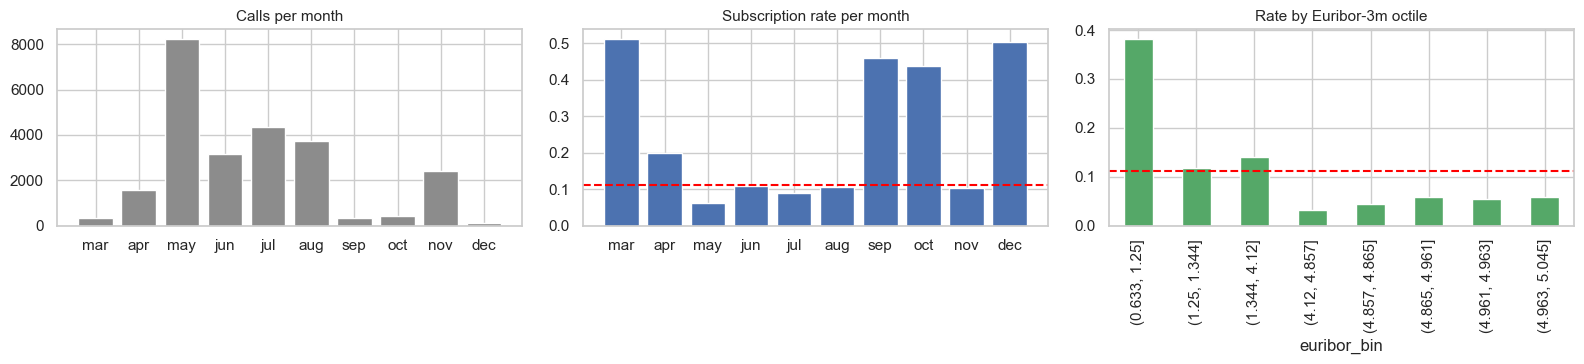

,calls,subscription_rate,mean_euribor3m
year_proxy,,,
2008,16622,0.050,4.818
2009,6851,0.191,1.230
2010,1232,0.520,0.812


calls                  rate              
year_proxy    2008    2009   2010   2008   2009   2010
month                                                 
apr            NaN  1469.0  111.0    NaN  0.171  0.559
aug         3118.0   475.0  152.0  0.056  0.326  0.487
dec            6.0   109.0    NaN  0.000  0.532    NaN
jul         4056.0   111.0  181.0  0.061  0.324  0.580
jun         2605.0   433.0  127.0  0.048  0.363  0.496
mar            NaN   158.0  164.0    NaN  0.462  0.561
may         4652.0  3461.0  129.0  0.030  0.087  0.581
nov         2154.0   191.0   75.0  0.060  0.476  0.427
oct           31.0   275.0  123.0  0.645  0.425  0.415
sep            NaN   169.0  170.0    NaN  0.408  0.512

In [16]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
g = eda.groupby("month")["target"].agg(rate="mean", calls="size").reindex(month_order)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(g.index, g["calls"], color="#8c8c8c"); ax[0].set_title("Calls per month")
ax[1].bar(g.index, g["rate"], color="#4c72b0"); ax[1].axhline(base, color="red", ls="--"); ax[1].set_title("Subscription rate per month")
d = eda.assign(euribor_bin=pd.qcut(eda["euribor3m"], 8, duplicates="drop"))
d.groupby("euribor_bin", observed=True)["target"].mean().plot.bar(ax=ax[2], color="#55a868"); ax[2].set_title("Rate by Euribor-3m octile"); ax[2].axhline(base, color="red", ls="--")
plt.tight_layout(); plt.show()
yr = eda.groupby("year_proxy").agg(calls=("target", "size"), subscription_rate=("target", "mean"), mean_euribor3m=("euribor3m", "mean")).round(3)
display(yr)
display(eda.groupby(["year_proxy", "month"]).agg(calls=("target", "size"), rate=("target", "mean")).round(3).unstack(0))

**Observations – time and the economy (the most important context finding)**
- The subscription rate rises from **5.0 % in 2008 to 19.1 % in 2009 and 52.0 % in 2010**, while the mean Euribor falls from 4.8 % to 1.2 % to 0.8 %. 2008 contains 67 % of all calls.
- The same month behaves very differently in different years (May: 3.0 % in 2008, 8.7 % in 2009, 58 % in 2010 with far fewer calls). **Month, year, the economy and the bank's calling strategy are confounded**, so month effects must not be read as pure seasonality.
- By Euribor octile, the lowest-rate octile subscribes at 38 % and the others at 3 – 14 %. The data cannot tell *why* (customer behaviour versus which customers were called in which period).
- Consequence: the process is **non-stationary**; a random split is optimistic. This is quantified in Section 11.

### 4.4 Outliers – the actual records

In [17]:
def iqr_summary(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    out = s[(s < lo) | (s > hi)]
    return pd.Series({"lower_fence": lo, "upper_fence": hi, "n_outliers": len(out), "pct": 100 * len(out) / len(s),
                      "rate_among_outliers": eda.loc[out.index, "target"].mean() if len(out) else np.nan})
display(eda[["age", "campaign", "previous", "cons.conf.idx"]].apply(iqr_summary).T.round(3))
print("The most extreme `campaign` records (>= 30 contacts):")
display(eda.loc[eda.campaign >= 30, ["age", "job", "contact", "campaign", "month", "year_proxy", "target"]].head(10))
print("The oldest customers (age >= 90):")
display(eda.loc[eda.age >= 90, ["age", "job", "campaign", "target"]])

,lower_fence,upper_fence,n_outliers,pct,rate_among_outliers
age,9.50,69.50,291.0,1.178,0.460
campaign,-2.00,6.00,1422.0,5.756,0.046
previous,0.00,0.00,3305.0,13.378,0.270
cons.conf.idx,-52.15,-26.95,275.0,1.113,0.425


The most extreme `campaign` records (>= 30 contacts):


,age,job,contact,campaign,month,year_proxy,target
18648,36,admin.,cellular,33,jul,2008,0
18787,53,self-employed,cellular,31,jul,2008,0
4113,52,entrepreneur,telephone,39,may,2008,0
10430,26,blue-collar,telephone,35,jun,2008,0
17333,42,self-employed,cellular,30,jul,2008,0
15946,27,blue-collar,telephone,31,jul,2008,0
12638,43,entrepreneur,cellular,30,jul,2008,0
4106,32,admin.,telephone,56,may,2008,0
18562,53,admin.,cellular,33,jul,2008,0
17978,38,admin.,cellular,30,jul,2008,0


The oldest customers (age >= 90):


,age,job,campaign,target
38440,98,retired,1,1
39722,92,retired,3,1
38443,98,retired,2,1
38011,91,retired,1,0
40438,92,retired,1,1
39643,92,retired,1,0
38021,91,retired,2,0


**Decision on outliers – retain, do not delete (evidence above)**
- `campaign` > 6 (5.8 % of rows) converts at only 4.6 %. The most extreme records (30 – 56 contacts, mostly May – July 2008, mainly telephone) are persistent-calling cases, and none of the 10 shown subscribed. They are real behaviour, not errors, and carry business information, so they are kept (the variable is excluded from the model for the leakage reason above).
- `age` ≥ 70 (1.2 %) converts at 46 %; the records ≥ 90 are plausible retired customers (4 of 7 subscribed). Removing them would remove a high-converting group.
- `previous` shows 13 % "outliers" only because its IQR is 0 (almost everyone is 0): these are simply customers contacted before, who convert at 27 %. `cons.conf.idx` values (1.1 %) are legitimate economic readings.

### 4.5 The `duration` variable

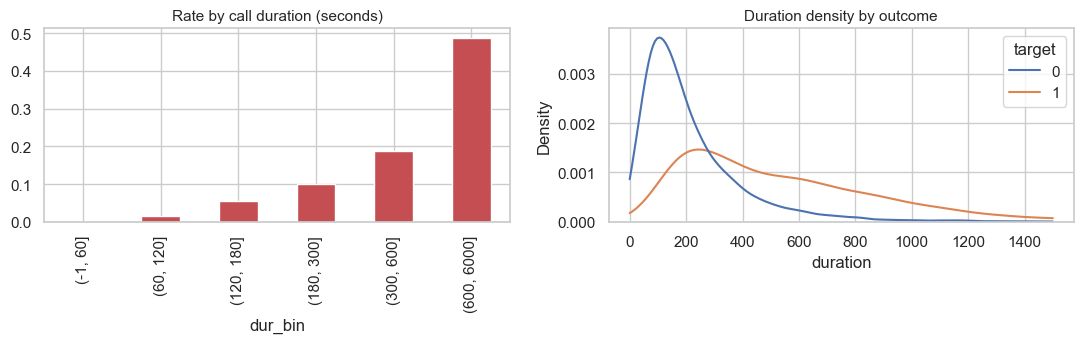

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
d = eda.assign(dur_bin=pd.cut(eda.duration, [-1, 60, 120, 180, 300, 600, 6000]))
d.groupby("dur_bin", observed=True)["target"].mean().plot.bar(ax=ax[0], color="#c44e52"); ax[0].set_title("Rate by call duration (seconds)")
sns.kdeplot(data=eda, x="duration", hue="target", common_norm=False, clip=(0, 1500), ax=ax[1]); ax[1].set_title("Duration density by outcome")
plt.tight_layout(); plt.show()

**Observation:** the subscription rate rises from **0 %** (calls under 60 s) through 1.7 %, 5.4 %, 10.0 %, 18.9 % to **48.9 %** for calls longer than 10 minutes. Duration is only known **after** the call, when the outcome is effectively decided. Using it to choose whom to call would be target leakage and would give a model that cannot be deployed, so it is **excluded from every production model** and used only for a labelled benchmark (10.1).

## 5. Preprocessing & feature engineering (Task 2 – part A)

Only **stateless, row-wise** transformations are written by hand; everything that learns from data (scaling, encoding, the model) lives inside the `Pipeline` and is fitted on training folds only.

| Issue found in EDA | Treatment | Reason |
|---|---|---|
| `duration` | removed | known only after the call (leakage) |
| `campaign` | removed | counts all contacts **including the call that produced the outcome**, and customers who subscribe presumably stop being called, so the total is not known before calling; the cross-validated check in 10.1 shows dropping it costs nothing |
| `pdays = 999` sentinel | → `prev_contacted` (0/1) + `pdays_days` (0 if never) | a numeric 999 would distort scaling and coefficients |
| U-shaped `age` effect | keep `age` **and** `age_group` | lets linear models represent the shape |
| `unknown` (6 columns) | own category | see 2.2 |
| `housing` / `loan` | + `has_any_loan` | cheap combined indicator |
| Categoricals | one-hot, unseen levels ignored | low cardinality (≤ 12) |
| Numeric scale | `StandardScaler` | needed by logistic regression, harmless otherwise |
| Collinear macro variables | kept; L2 / trees; ablation in 10.1 | see VIF table below |
| Duplicates | removed before the split | row-wise, learns nothing (2.3) |

*Equal spacing of ordinal-like fields is not assumed:* `age_group` and `month` are one-hot encoded, not mapped to numbers.

In [19]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    # Stateless, row-wise feature construction: nothing is learned from the data, so it cannot leak.
    def __init__(self, drop_duration=True, drop_macro=False, keep_campaign=False):
        self.drop_duration = drop_duration
        self.drop_macro = drop_macro
        self.keep_campaign = keep_campaign
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["prev_contacted"] = (X["pdays"] != 999).astype(int)
        X["pdays_days"] = X["pdays"].where(X["pdays"] != 999, 0)
        X["age_group"] = pd.cut(X["age"], [0, 25, 35, 45, 55, 65, 120],
                                labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"]).astype(str)
        X["has_any_loan"] = ((X["housing"] == "yes") | (X["loan"] == "yes")).astype(int)
        if self.keep_campaign:
            X["campaign_log"] = np.log1p(X["campaign"])
        X = X.drop(columns=["pdays", "campaign"])
        if self.drop_duration:
            X = X.drop(columns=["duration"])
        if self.drop_macro:
            X = X.drop(columns=["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"])
        return X

def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:                       # older scikit-learn
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_pipeline(model):
    prep = ColumnTransformer([("num", StandardScaler(), selector(dtype_include="number")),
                              ("cat", make_ohe(), selector(dtype_exclude="number"))])
    return Pipeline([("fe", FeatureEngineer()), ("prep", prep), ("clf", model)])

fe_fit = FeatureEngineer().fit_transform(X_fit)
print("Model input columns (", fe_fit.shape[1], "):", list(fe_fit.columns))

Model input columns ( 21 ): ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'prev_contacted', 'pdays_days', 'age_group', 'has_any_loan']


### 5.1 Checks on the engineered features
The previous project lacked checks for impossible engineered values, skew and multicollinearity after feature creation; they are done here.

In [20]:
assert (fe_fit["pdays_days"] >= 0).all(), "negative pdays_days"
assert fe_fit["prev_contacted"].isin([0, 1]).all() and fe_fit["has_any_loan"].isin([0, 1]).all()
assert (fe_fit["age_group"] != "nan").all(), "age outside the bins"
assert not fe_fit.isna().any().any(), "NaN after feature engineering"
print("Range checks passed: no impossible or missing engineered values.")

num_fe = fe_fit.select_dtypes("number")
Z = (num_fe - num_fe.mean()) / num_fe.std()
vif = {}
for c in Z.columns:
    others = Z.drop(columns=c); r2 = LinearRegression().fit(others, Z[c]).score(others, Z[c])
    vif[c] = 1 / (1 - r2) if r2 < 1 else np.inf
display(pd.DataFrame({"VIF": pd.Series(vif).round(1), "skew": num_fe.skew().round(2)}).sort_values("VIF", ascending=False))

Range checks passed: no impossible or missing engineered values.


,VIF,skew
euribor3m,64.2,-0.71
emp.var.rate,33.6,-0.73
nr.employed,31.6,-1.04
cons.price.idx,6.4,-0.24
prev_contacted,4.0,4.94
pdays_days,3.3,8.04
cons.conf.idx,2.6,0.31
previous,1.8,3.91
age,1.0,0.80
has_any_loan,1.0,-0.36


VIF above ~10 flags severe multicollinearity. It is concentrated in the economic variables (`euribor3m`, `emp.var.rate`, `nr.employed`, `cons.price.idx`), as seen in 4.1. They are kept (removing them by hand would discard real signal), and the models used (L2-regularised logistic regression, tree ensembles) tolerate collinearity; 10.1 measures what these variables contribute and and Section 11 shows how stable that is over time.

## 6. Evaluation framework
- **Primary selection metric: PR-AUC (average precision)** – the positive class is only 11 % of the data, and PR-AUC focuses on finding subscribers. **ROC-AUC** (ranking quality) is reported next to it.
- At the end: **precision / recall / F1 / accuracy at a tuned threshold**, lift, calibration and bootstrap confidence intervals.
- Model comparison and tuning: **5-fold stratified cross-validation inside the training part only**.

In [21]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
cv5b = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)      # fresh folds for the final selection
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()
print("Imbalance ratio (neg/pos) in the training part = %.2f" % pos_weight)

def cv_summary(est, cv=cv5):
    r = cross_validate(est, X_fit, y_fit, cv=cv, scoring=SCORING, n_jobs=1)
    return {"PR-AUC mean": r["test_pr_auc"].mean(), "PR-AUC sd": r["test_pr_auc"].std(),
            "ROC-AUC mean": r["test_roc_auc"].mean(), "ROC-AUC sd": r["test_roc_auc"].std(), "fit_s": r["fit_time"].mean()}

Imbalance ratio (neg/pos) in the training part = 7.88


## 7. Model comparison (Task 2 – part B)

### 7.1 Baselines with default settings (5-fold CV on the training part)

In [22]:
baselines = {
    "Dummy (prior)":        DummyClassifier(strategy="prior"),
    "Logistic Regression":  LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree":        DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RS),
    "Random Forest":        RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RS),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RS),
    "XGBoost":              XGBClassifier(n_estimators=250, learning_rate=0.05, max_depth=4, eval_metric="logloss",
                                          scale_pos_weight=pos_weight, n_jobs=1, random_state=RS),
}
baseline_df = pd.DataFrame({n: cv_summary(make_pipeline(m)) for n, m in baselines.items()}).T.sort_values("PR-AUC mean", ascending=False)
display(baseline_df.round(4))

,PR-AUC mean,PR-AUC sd,ROC-AUC mean,ROC-AUC sd,fit_s
HistGradientBoosting,0.4538,0.0143,0.7888,0.0122,1.0235
Random Forest,0.4520,0.0109,0.7816,0.0119,2.6474
XGBoost,0.4517,0.0114,0.7888,0.0091,2.1182
Logistic Regression,0.4425,0.0140,0.7829,0.0063,0.6170
Decision Tree,0.4077,0.0104,0.7709,0.0043,0.3175
Dummy (prior),0.1126,0.0001,0.5000,0.0000,0.2035


**Findings – baselines (5-fold CV on the training part)**
- The Dummy model's PR-AUC (0.113) equals the positive rate – the floor. Every real model is far above it.
- **Random Forest, HistGradientBoosting and XGBoost are practically tied** (PR-AUC 0.452 – 0.454, ROC-AUC 0.78 – 0.79); Logistic Regression is slightly lower (0.443) and a depth-6 Decision Tree lower still (0.408). The signal is largely simple, so extra complexity buys little.

### 7.2 Hyper-parameter tuning – the same procedure for every serious candidate
Logistic Regression, Random Forest, HistGradientBoosting and XGBoost are each tuned with `RandomizedSearchCV`: **same folds, same metric (PR-AUC), same number of sampled configurations (10)**. The search is deliberately small to fit a single-CPU budget; the gains from tuning turn out to be small anyway (see 7.4).

In [23]:
N_ITER = 10
searches = {
 "Logistic Regression": (LogisticRegression(max_iter=3000), {
        "clf__C": loguniform(1e-3, 1e2), "clf__class_weight": [None, "balanced"]}),
 "Random Forest": (RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=RS), {
        "clf__max_depth": [6, 8, 12, None], "clf__min_samples_leaf": [3, 10, 30, 60],
        "clf__max_features": ["sqrt", 0.3], "clf__class_weight": [None, "balanced_subsample"]}),
 "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=RS), {
        "clf__learning_rate": loguniform(0.02, 0.2), "clf__max_depth": [3, 4, 6, None],
        "clf__max_leaf_nodes": [15, 31, 63], "clf__min_samples_leaf": [20, 50, 100],
        "clf__l2_regularization": loguniform(1e-3, 10), "clf__max_iter": [150, 300]}),
 "XGBoost": (XGBClassifier(eval_metric="logloss", n_jobs=1, random_state=RS), {
        "clf__n_estimators": [150, 300], "clf__learning_rate": loguniform(0.02, 0.2),
        "clf__max_depth": [3, 4, 5, 6], "clf__min_child_weight": [1, 5, 10],
        "clf__subsample": uniform(0.7, 0.3), "clf__colsample_bytree": uniform(0.6, 0.4),
        "clf__reg_lambda": loguniform(0.1, 20), "clf__scale_pos_weight": [1, 3, pos_weight]}),
}
tuned = {}
for name, (est, space) in searches.items():
    rs = RandomizedSearchCV(make_pipeline(est), space, n_iter=N_ITER, scoring="average_precision", cv=cv5,
                            random_state=RS, n_jobs=1, refit=True)
    rs.fit(X_fit, y_fit)
    tuned[name] = rs.best_estimator_
    print("%-22s search PR-AUC %.4f  %s" % (name, rs.best_score_,
          {k.replace("clf__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in rs.best_params_.items()}))

Logistic Regression    search PR-AUC 0.4459  {'C': 0.9847, 'class_weight': None}
Random Forest          search PR-AUC 0.4583  {'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 8, 'class_weight': None}
HistGradientBoosting   search PR-AUC 0.4564  {'l2_regularization': 0.0042, 'learning_rate': 0.0286, 'max_depth': 6, 'max_iter': 150, 'max_leaf_nodes': 15, 'min_samples_leaf': 100}
XGBoost                search PR-AUC 0.4622  {'colsample_bytree': 0.7247, 'learning_rate': 0.0662, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 150, 'reg_lambda': 17.0233, 'scale_pos_weight': 3, 'subsample': 0.8349}


**Findings – tuning:** the best XGBoost configuration uses shallow trees (depth 4), a low learning rate (0.066), strong L2 regularisation (λ ≈ 17) and a moderate positive-class weight (3 instead of the full 7.9). HistGradientBoosting also chose a low learning rate (0.029) with large leaves (at least 100 samples); Random Forest preferred depth 8 with `max_features = 0.3`. The next cells quantify what tuning gained.

### 7.3 Final selection – rule fixed in advance, fresh folds
Search scores are slightly optimistic because they were used to choose the configuration. Each tuned pipeline is therefore re-scored with **fresh cross-validation folds**. **Rule:** the model with the highest mean PR-AUC becomes the single final model. Models within one standard deviation of the best are listed as statistically tied (reported, not hidden). The validation and test sets play no role.

In [24]:
tuned_df = pd.DataFrame({n: cv_summary(clone(p), cv=cv5b) for n, p in tuned.items()}).T.sort_values("PR-AUC mean", ascending=False)
display(tuned_df.round(4))
FINAL_NAME = tuned_df.index[0]
best_m, best_s = tuned_df["PR-AUC mean"].iloc[0], tuned_df["PR-AUC sd"].iloc[0]
tied = tuned_df[tuned_df["PR-AUC mean"] >= best_m - best_s].index.tolist()
print(">>> FINAL MODEL:", FINAL_NAME)
print("Statistically tied with the best (within 1 SD):", tied)
final_est = clone(tuned[FINAL_NAME])

,PR-AUC mean,PR-AUC sd,ROC-AUC mean,ROC-AUC sd,fit_s
XGBoost,0.4601,0.0144,0.7903,0.0047,1.7664
HistGradientBoosting,0.4572,0.0148,0.7895,0.0062,1.7039
Random Forest,0.4567,0.0135,0.7898,0.0071,2.2398
Logistic Regression,0.4479,0.0155,0.7837,0.0074,0.6509


>>> FINAL MODEL: XGBoost
Statistically tied with the best (within 1 SD): ['XGBoost', 'HistGradientBoosting', 'Random Forest', 'Logistic Regression']


**Findings – selection (fresh CV folds, training part only)**
- **XGBoost has the highest mean PR-AUC (0.4601)** and is selected as the single final model by the pre-defined rule.
- HistGradientBoosting (0.4572), Random Forest (0.4567) and even Logistic Regression (0.4479) are **within one standard deviation** (≈ 0.015): the models are statistically tied. This is reported openly; XGBoost is not claimed to be clearly superior. It is chosen because it is first by the rule, fast to train, handles the imbalance through a tuned positive-class weight, and gives importances.
- ROC-AUC is essentially identical for the three ensembles (0.7895 – 0.7903).

### 7.4 Did tuning help? And what does complexity buy?

,default PR-AUC,tuned PR-AUC,default ROC-AUC,tuned ROC-AUC,PR-AUC change
HistGradientBoosting,0.4538,0.4572,0.7888,0.7895,0.0034
Logistic Regression,0.4425,0.4479,0.7829,0.7837,0.0053
Random Forest,0.4520,0.4567,0.7816,0.7898,0.0047
XGBoost,0.4517,0.4601,0.7888,0.7903,0.0084


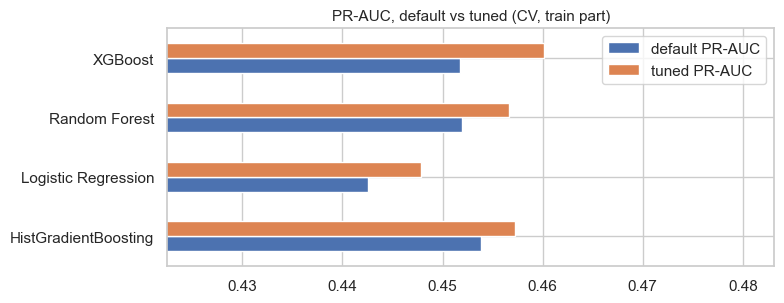

Accuracy-vs-complexity: XGBoost PR-AUC 0.4601 vs Logistic Regression 0.4479 (gain 0.0123); fit time 1.77s vs 0.65s


In [25]:
cmp = pd.DataFrame({"default PR-AUC": baseline_df["PR-AUC mean"], "tuned PR-AUC": tuned_df["PR-AUC mean"],
                    "default ROC-AUC": baseline_df["ROC-AUC mean"], "tuned ROC-AUC": tuned_df["ROC-AUC mean"]}).dropna()
cmp["PR-AUC change"] = cmp["tuned PR-AUC"] - cmp["default PR-AUC"]
display(cmp.round(4))
cmp[["default PR-AUC", "tuned PR-AUC"]].plot.barh(figsize=(8, 3.2)); plt.xlim(cmp[["default PR-AUC", "tuned PR-AUC"]].min().min() - .02, None)
plt.title("PR-AUC, default vs tuned (CV, train part)"); plt.tight_layout(); plt.show()
if FINAL_NAME != "Logistic Regression":
    lr, fin = tuned_df.loc["Logistic Regression"], tuned_df.loc[FINAL_NAME]
    print("Accuracy-vs-complexity: %s PR-AUC %.4f vs Logistic Regression %.4f (gain %.4f); fit time %.2fs vs %.2fs"
          % (FINAL_NAME, fin["PR-AUC mean"], lr["PR-AUC mean"], fin["PR-AUC mean"] - lr["PR-AUC mean"], fin["fit_s"], lr["fit_s"]))

**Findings – tuning and complexity**
- Tuning **improved every model and worsened none** (PR-AUC +0.003 to +0.008), but the gains are small compared with the fold-to-fold spread, so the default models were already near the plateau for this feature set. Better *information* (additional customer features), not further tuning, is what could move performance.
- **Accuracy-vs-complexity trade-off:** XGBoost beats the transparent Logistic Regression by only **0.012 PR-AUC** (0.460 vs 0.448); both train in a couple of seconds. If transparency matters more than ≈ 1 PR-AUC point, Logistic Regression is a defensible alternative.

## 8. Decision threshold and calibration data — from the validation set
The final model is fitted **once** on the training part. Its predictions on the **validation set** (which no earlier step has seen) are used to choose the F1-optimal threshold. The model is **not refitted afterwards**, so the threshold belongs to exactly the model that is evaluated on the test set. (Hyper-parameters were tuned on training-part folds only, so the threshold is independent of tuning.)

Selected threshold (max F1 on the validation set) = 0.474
Validation: ROC-AUC 0.8126 | PR-AUC 0.4582 | precision 0.462 | recall 0.551 | F1 0.502 | accuracy 0.8770


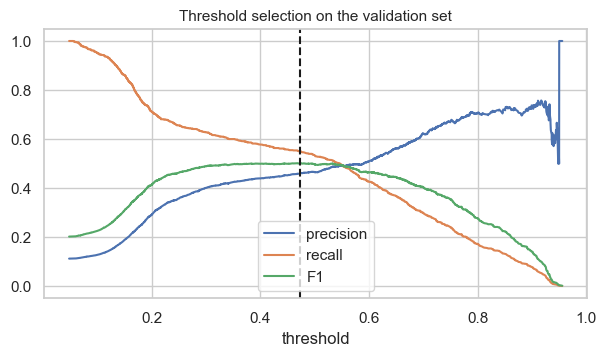

In [26]:
final_model = final_est.fit(X_fit, y_fit)
p_val = final_model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
THR = float(thr[np.argmax(f1s[:-1])])
pv = (p_val >= THR).astype(int)
print("Selected threshold (max F1 on the validation set) = %.3f" % THR)
print("Validation: ROC-AUC %.4f | PR-AUC %.4f | precision %.3f | recall %.3f | F1 %.3f | accuracy %.4f"
      % (roc_auc_score(y_val, p_val), average_precision_score(y_val, p_val), precision_score(y_val, pv),
         recall_score(y_val, pv), f1_score(y_val, pv), accuracy_score(y_val, pv)))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thr, prec[:-1], label="precision"); ax.plot(thr, rec[:-1], label="recall"); ax.plot(thr, f1s[:-1], label="F1")
ax.axvline(THR, color="k", ls="--"); ax.set_xlabel("threshold"); ax.set_title("Threshold selection on the validation set"); ax.legend(); plt.show()

**Findings – threshold (validation set):** the F1-optimal threshold is **0.474**; at it the validation set gives precision 0.462, recall 0.551, F1 0.502. The F1 curve is flat around its maximum, so the exact value is not fragile.

In [27]:
# Accuracy is NOT the objective: show what each threshold would give on the VALIDATION set (not the test set)
rows = []
for t in [0.2, 0.3, 0.4, THR, 0.5, 0.6, 0.7]:
    q = (p_val >= t).astype(int)
    rows.append({"threshold": round(t, 3), "accuracy": accuracy_score(y_val, q), "recall": recall_score(y_val, q),
                 "precision": precision_score(y_val, q, zero_division=0), "F1": f1_score(y_val, q)})
display(pd.DataFrame(rows).round(4).set_index("threshold"))
print("Naive 'always no' accuracy on the validation set: %.4f" % (1 - y_val.mean()))

,accuracy,recall,precision,F1
threshold,,,,
0.200,0.7716,0.7112,0.2904,0.4124
0.300,0.8525,0.6282,0.4012,0.4897
0.400,0.8693,0.5776,0.4393,0.4991
0.474,0.8770,0.5506,0.4616,0.5022
0.500,0.8786,0.5345,0.4662,0.4980
0.600,0.8890,0.4256,0.5090,0.4636
0.700,0.9005,0.2985,0.6225,0.4035


Naive 'always no' accuracy on the validation set: 0.8873


**Reading the table:** accuracy *rises* as the threshold rises, but only because the model then flags fewer customers and misses more buyers: at a threshold of 0.70 accuracy is 90.0 % while recall falls to 30 %. The "always no" accuracy (88.7 %) shows why accuracy alone is a poor target here; the F1-optimal threshold is used as a neutral default, and the bank should set the real threshold from its own cost of a call and value of a deposit.

## 9. Final evaluation on the test set (touched once)
The frozen model and threshold are applied to the test set one time. Only the selected model is evaluated here; comparing several models on the test set would turn it into a second selection set. Confidence intervals come from a bootstrap of the test predictions.

### 9.1 Metrics with 95 % bootstrap intervals

,estimate,95% CI low,95% CI high
ROC-AUC,0.8116,0.7930,0.8277
PR-AUC,0.4783,0.4445,0.5128
Precision,0.4771,0.4463,0.5081
Recall,0.5614,0.5283,0.5914
F1,0.5158,0.4880,0.5412
Accuracy,0.8813,0.8738,0.8883
Balanced accuracy,0.7416,0.7246,0.7570


Test positive rate = 0.1127 (PR-AUC of a random model) | naive 'always no' accuracy = 0.8873 | threshold = 0.474


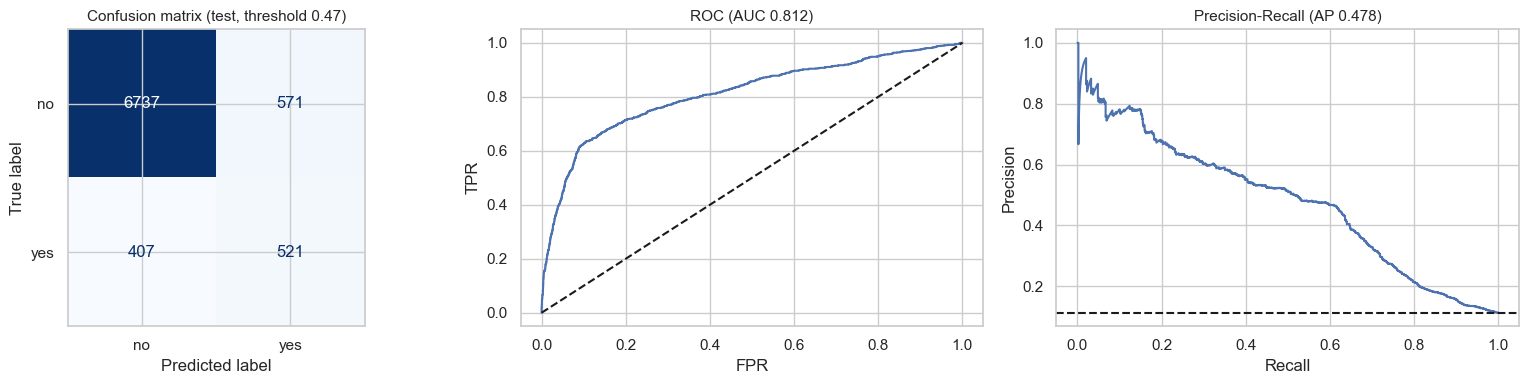

In [28]:
p_test = final_model.predict_proba(X_test)[:, 1]
yt = y_test.values
pred = (p_test >= THR).astype(int)
names = ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1", "Accuracy", "Balanced accuracy"]
def metric_row(y, p, q):
    return [roc_auc_score(y, p), average_precision_score(y, p), precision_score(y, q, zero_division=0),
            recall_score(y, q), f1_score(y, q), accuracy_score(y, q), balanced_accuracy_score(y, q)]
point = metric_row(yt, p_test, pred)
rng = np.random.RandomState(RS); boots = []
for _ in range(1000):
    s = rng.choice(len(yt), len(yt), replace=True)
    boots.append(metric_row(yt[s], p_test[s], (p_test[s] >= THR).astype(int)))
lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
res_tbl = pd.DataFrame({"estimate": point, "95% CI low": lo, "95% CI high": hi}, index=names)
display(res_tbl.round(4))
print("Test positive rate = %.4f (PR-AUC of a random model) | naive 'always no' accuracy = %.4f | threshold = %.3f" % (yt.mean(), 1 - yt.mean(), THR))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(yt, pred, display_labels=["no", "yes"], cmap="Blues", ax=ax[0], colorbar=False); ax[0].set_title("Confusion matrix (test, threshold %.2f)" % THR)
fpr, tpr, _ = roc_curve(yt, p_test); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (AUC %.3f)" % point[0]); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
pr, rc, _ = precision_recall_curve(yt, p_test); ax[2].plot(rc, pr); ax[2].axhline(yt.mean(), color="k", ls="--"); ax[2].set_title("Precision-Recall (AP %.3f)" % point[1]); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
plt.tight_layout(); plt.show()

**Findings – final test performance (XGBoost, threshold 0.474, test set used once)**
- **ROC-AUC 0.812 (95 % CI 0.793 – 0.828)** and **PR-AUC 0.478 (0.445 – 0.513)**, about 4.2 × the 0.113 of a random model. Precision 0.477, **recall 0.561**, F1 0.516, balanced accuracy 0.742.
- **Accuracy is 88.1 % (CI 87.4 – 88.8 %)**, statistically indistinguishable from the 88.7 % of always answering "no". That is expected, not a failure: the model is tuned to *find buyers*, and ≈ 48 % of the customers it flags subscribe (vs 11 % at random) while it finds 56 % of all buyers.
- The test result agrees with cross-validation (PR-AUC 0.460) and with the validation set (0.458), so there is no sign of overfitting to the training folds.

### 9.2 Ranking value for the marketing team (gains / lift) — independent of any threshold

,customers,subscribers,rate,lift,cum_share_of_subscribers
decile,,,,,
1,824,430,0.522,4.631,0.463
2,824,187,0.227,2.014,0.665
3,823,67,0.081,0.723,0.737
4,824,50,0.061,0.539,0.791
5,823,39,0.047,0.421,0.833
6,824,42,0.051,0.452,0.878
7,823,29,0.035,0.313,0.909
8,824,35,0.042,0.377,0.947
9,823,24,0.029,0.259,0.973


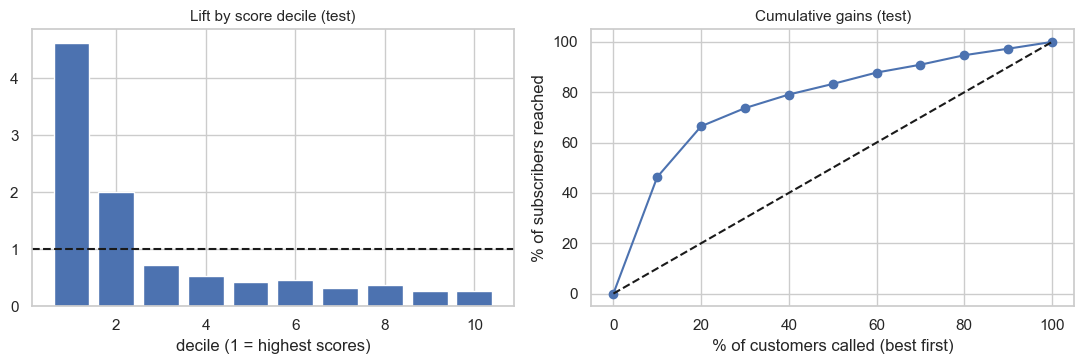

In [29]:
res = pd.DataFrame({"y": yt, "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
res["decile"] = pd.qcut(res.index, 10, labels=range(1, 11))
dec = res.groupby("decile", observed=True).agg(customers=("y", "size"), subscribers=("y", "sum"), rate=("y", "mean"))
dec["lift"] = dec["rate"] / yt.mean(); dec["cum_share_of_subscribers"] = dec["subscribers"].cumsum() / dec["subscribers"].sum()
display(dec.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(dec.index.astype(int), dec["lift"], color="#4c72b0"); ax[0].axhline(1, color="k", ls="--"); ax[0].set_title("Lift by score decile (test)"); ax[0].set_xlabel("decile (1 = highest scores)")
ax[1].plot([0] + list(dec.index.astype(int) * 10), [0] + list(dec["cum_share_of_subscribers"] * 100), "o-"); ax[1].plot([0, 100], [0, 100], "k--")
ax[1].set_xlabel("% of customers called (best first)"); ax[1].set_ylabel("% of subscribers reached"); ax[1].set_title("Cumulative gains (test)")
plt.tight_layout(); plt.show()

**Findings – business view (test set)**
- **Top decile:** 52.2 % subscribe (lift 4.6 ×) and it holds 46 % of all subscribers; the **top 20 % hold 66 %** and the **top 30 % hold 74 %**, at ≈ 28 % conversion instead of 11 % – about 70 % fewer calls. The bottom half of the list holds only ≈ 17 % of the subscribers.
- This holds while the economic conditions resemble the training period; Section 11 shows how much weaker it is for later periods (top 30 % then holds 48 % of subscribers).

### 9.3 Calibration — are the probabilities trustworthy?
Isotonic calibration is **learned on the validation predictions** (never on the test set) and applied to the test set.

Brier score  raw: 0.0904 | calibrated: 0.0759 | constant base-rate model: 0.1000
Mean predicted probability  raw: 0.225 | calibrated: 0.112 | observed rate: 0.113


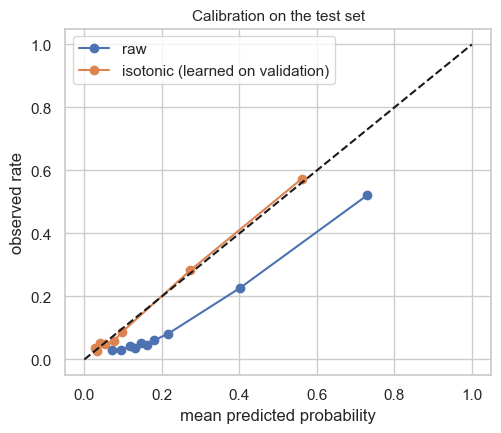

In [30]:
iso = IsotonicRegression(out_of_bounds="clip").fit(p_val, y_val)
p_cal = iso.predict(p_test)
print("Brier score  raw: %.4f | calibrated: %.4f | constant base-rate model: %.4f"
      % (brier_score_loss(yt, p_test), brier_score_loss(yt, p_cal), brier_score_loss(yt, np.full(len(yt), y_fit.mean()))))
print("Mean predicted probability  raw: %.3f | calibrated: %.3f | observed rate: %.3f" % (p_test.mean(), p_cal.mean(), yt.mean()))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for lab, p in [("raw", p_test), ("isotonic (learned on validation)", p_cal)]:
    fp_, mp_ = calibration_curve(yt, p, n_bins=10, strategy="quantile"); ax.plot(mp_, fp_, "o-", label=lab)
ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed rate"); ax.legend(); ax.set_title("Calibration on the test set"); plt.show()

**Findings – calibration:** the raw probabilities are **too high** (mean 0.225 vs an observed 0.113) because the model was trained with a positive-class weight. Isotonic calibration learned on the *validation* set fixes this on the test set (mean 0.112) and lowers the Brier score from 0.0904 to 0.0759 (a constant base-rate model scores 0.1000). Use the raw scores only for ranking; use the calibrated probabilities when a real probability is needed (e.g. expected revenue).

### 9.4 Subgroup error analysis (diagnostic only – no decision is based on it)

In [31]:
seg = X_test.copy(); seg["y"] = yt; seg["p"] = p_test; seg["pred"] = pred
seg["age_group"] = pd.cut(seg.age, [0, 25, 35, 45, 55, 65, 120], labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])
def seg_table(col):
    g = seg.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(), "actual_rate": g["y"].mean(), "mean_score": g["p"].mean(),
                         "ROC-AUC": g.apply(lambda d: roc_auc_score(d.y, d.p) if 0 < d.y.sum() < len(d) else np.nan),
                         "recall": g.apply(lambda d: recall_score(d.y, d.pred) if d.y.sum() else np.nan),
                         "precision": g.apply(lambda d: precision_score(d.y, d.pred, zero_division=0) if d.pred.sum() else np.nan)}).round(3)
for c in ["contact", "age_group", "poutcome", "month", "job"]:
    print("---", c); display(seg_table(c))

--- contact


,n,actual_rate,mean_score,ROC-AUC,recall,precision
contact,,,,,,
cellular,5196,0.147,0.278,0.815,0.620,0.481
telephone,3040,0.054,0.133,0.694,0.287,0.439


--- age_group


,n,actual_rate,mean_score,ROC-AUC,recall,precision
age_group,,,,,,
<=25,328,0.189,0.374,0.840,0.790,0.445
26-35,2953,0.124,0.238,0.804,0.512,0.464
36-45,2594,0.091,0.184,0.785,0.481,0.579
46-55,1655,0.075,0.186,0.783,0.548,0.450
56-65,596,0.143,0.273,0.799,0.600,0.395
65+,110,0.500,0.683,0.641,0.945,0.510


--- poutcome


,n,actual_rate,mean_score,ROC-AUC,recall,precision
poutcome,,,,,,
failure,837,0.152,0.285,0.813,0.654,0.393
nonexistent,7120,0.088,0.195,0.768,0.424,0.430
success,279,0.616,0.806,0.747,0.994,0.658


--- month


,n,actual_rate,mean_score,ROC-AUC,recall,precision
month,,,,,,
apr,547,0.208,0.369,0.825,0.553,0.457
aug,1223,0.100,0.219,0.801,0.541,0.415
dec,37,0.432,0.699,0.631,1.000,0.457
jul,1416,0.083,0.193,0.685,0.316,0.521
jun,1070,0.110,0.227,0.831,0.712,0.464
mar,114,0.535,0.717,0.565,0.934,0.518
may,2748,0.066,0.146,0.714,0.181,0.458
nov,836,0.099,0.223,0.820,0.639,0.546
oct,136,0.456,0.690,0.695,0.984,0.480


--- job


,n,actual_rate,mean_score,ROC-AUC,recall,precision
job,,,,,,
admin.,2150,0.132,0.252,0.845,0.640,0.500
blue-collar,1813,0.067,0.160,0.682,0.221,0.491
entrepreneur,297,0.081,0.187,0.727,0.417,0.476
housemaid,201,0.085,0.216,0.928,0.765,0.520
management,584,0.110,0.218,0.807,0.562,0.480
retired,330,0.230,0.403,0.820,0.842,0.441
self-employed,307,0.111,0.241,0.828,0.559,0.396
services,786,0.081,0.177,0.689,0.344,0.468
student,184,0.283,0.465,0.801,0.827,0.467


**Findings – subgroup errors (test set; diagnostic only)**
- Precision is fairly uniform (≈ 0.39 – 0.66), but **recall differs a lot**. It is high where subscription is common: previous success 0.99 (precision 0.66), students 0.83, retired 0.84, age ≤ 25 0.79. It is low where subscription is rare: **May 0.18, blue-collar 0.22, telephone 0.29, July 0.32, services 0.34**.
- Ranking quality is best for cellular contact (ROC-AUC 0.82 vs 0.69 for telephone). The model therefore separates "promising" from "hopeless" segments well but misses subscribers hidden in low-converting segments; extra customer features would be needed there.
- Small groups (March n = 114, December n = 37, age 65+ n = 110, unknown job n = 63) give unstable estimates and should not be over-interpreted.

## 10. Robustness checks (training cross-validation and validation set – the test set stays untouched)

### 10.1 Feature-set ablations and the leakage benchmark (5-fold CV on the training part)

In [32]:
variants = {"final model (as selected)": {},
            "without the 5 economic variables": {"fe__drop_macro": True},
            "with campaign (log) added": {"fe__keep_campaign": True},
            "with duration  (benchmark - NOT usable)": {"fe__drop_duration": False}}
display(pd.DataFrame({lab: cv_summary(clone(final_est).set_params(**kw)) for lab, kw in variants.items()}).T[["PR-AUC mean", "PR-AUC sd", "ROC-AUC mean", "ROC-AUC sd"]].round(4))

,PR-AUC mean,PR-AUC sd,ROC-AUC mean,ROC-AUC sd
final model (as selected),0.4622,0.0092,0.7904,0.0088
without the 5 economic variables,0.4172,0.0142,0.7659,0.0060
with campaign (log) added,0.4607,0.0116,0.7903,0.0101
with duration (benchmark - NOT usable),0.6620,0.0071,0.9472,0.0025


**Findings – ablations (CV, training part)**
- **Duration benchmark:** adding `duration` would lift PR-AUC from 0.462 to 0.662 and ROC-AUC from 0.79 to 0.95 – an illusion of skill that cannot exist at prediction time.
- **`campaign`:** adding it back gives no gain (PR-AUC 0.461 vs 0.462), so excluding it costs nothing and removes the leakage concern.
- **Economic variables:** removing them lowers PR-AUC by 0.045 (0.462 → 0.417). They help a lot *inside* the period covered by the training data; Section 11 tests whether that carries over to the future.

### 10.2 Model interpretation (validation set, permutation importance)
Permutation importance on the raw input columns with the full pipeline (every dummy of a categorical variable is shuffled together). It reflects *predictive* importance, not causation, and captures non-linear and categorical effects that Pearson correlation cannot.

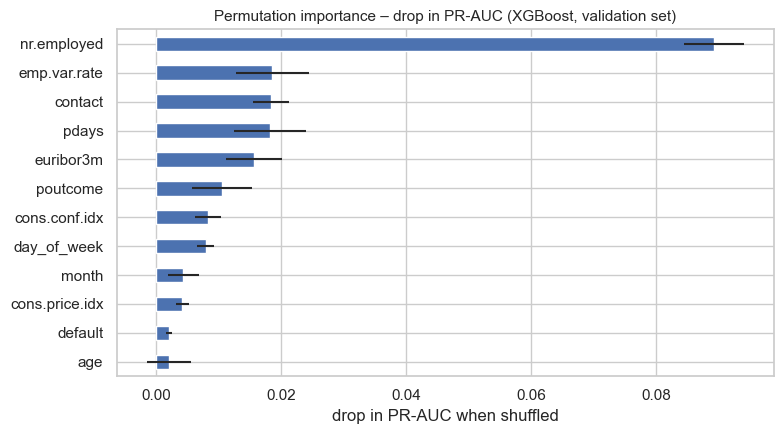

,mean,std
nr.employed,0.0892,0.0048
emp.var.rate,0.0186,0.0058
contact,0.0184,0.0028
pdays,0.0183,0.0058
euribor3m,0.0157,0.0045
poutcome,0.0106,0.0048
cons.conf.idx,0.0084,0.0020
day_of_week,0.0080,0.0014
month,0.0044,0.0025
cons.price.idx,0.0042,0.0010


In [33]:
pi = permutation_importance(final_model, X_val, y_val, scoring="average_precision", n_repeats=5, random_state=RS, n_jobs=1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_val.columns).drop(index=["duration", "campaign"], errors="ignore").sort_values("mean")
imp.tail(12).plot.barh(y="mean", xerr="std", legend=False, figsize=(8, 4.5), color="#4c72b0")
plt.title("Permutation importance – drop in PR-AUC (%s, validation set)" % FINAL_NAME); plt.xlabel("drop in PR-AUC when shuffled"); plt.tight_layout(); plt.show()
display(imp.sort_values("mean", ascending=False).head(10).round(4))

**Findings – what drives the predictions (validation set, drop in PR-AUC)**
1. **`nr.employed` (0.089)** by a wide margin, then `emp.var.rate` (0.019), **`contact` (0.018)**, `pdays` (0.018, previous contact), `euribor3m` (0.016) and `poutcome` (0.011); `cons.conf.idx`, `day_of_week`, `month` and `cons.price.idx` follow.
2. The economic variables are highly correlated, so they **share** credit (shuffling one lets the others compensate); each bar is individually under-stated and the economic regime as a group is even more important than shown.
3. The levers the bank can act on are previous-contact history, contact channel and timing. `housing`, `loan`, `marital` and `education` are not among the top ten.
4. Importance is *predictive*, not causal: cellular contact is associated with more subscriptions, but this dataset cannot prove that switching a customer to cellular would cause one.

## 11. Temporal stress test — how will the model behave on *future* campaigns?
The random split above mixes 2008, 2009 and 2010. Here the same final configuration is trained only on the past and tested on the future. This section is **diagnostic**: it uses its own splits, and no decision in this notebook depends on it. It matters because the base rate of subscription changes enormously over time (≈ 5 % in 2008, ≈ 20 % in 2009, ≈ 52 % in 2010).

### 11.1 Chronological hold-out (first 80 % of the rows → last 20 %)

In [34]:
def top_share(y, p, frac=0.30):
    k = int(len(y) * frac); idx = np.argsort(-p)[:k]; return y[idx].sum() / y.sum()

cut = int(len(df) * 0.80)
Xa, ya = X_all.iloc[:cut], y_all.iloc[:cut]; Xb, yb = X_all.iloc[cut:], y_all.iloc[cut:]
mt = clone(final_est).fit(Xa, ya); pb = mt.predict_proba(Xb)[:, 1]; qb = (pb >= THR).astype(int)
random_vs_time = pd.DataFrame({
    "random split (test set, Section 9)": [point[0], point[1], yt.mean(), top_share(yt, p_test), recall_score(yt, pred), accuracy_score(yt, pred)],
    "chronological hold-out (last 20 % of rows)": [roc_auc_score(yb, pb), average_precision_score(yb, pb), yb.mean(), top_share(yb.values, pb),
                                                    recall_score(yb, qb), accuracy_score(yb, qb)]},
    index=["ROC-AUC", "PR-AUC", "positive rate", "share of subscribers in top 30 % of scores", "recall at the validation threshold", "accuracy at the validation threshold"])
display(random_vs_time.round(4))

,"random split (test set, Section 9)",chronological hold-out (last 20 % of rows)
ROC-AUC,0.8116,0.6637
PR-AUC,0.4783,0.4635
positive rate,0.1127,0.3083
share of subscribers in top 30 % of scores,0.7371,0.4793
recall at the validation threshold,0.5614,0.1367
accuracy at the validation threshold,0.8813,0.6960


**Findings – chronological hold-out (diagnostic):** trained only on the first 80 % of the rows and tested on the last 20 % (the "future"), ROC-AUC falls from **0.81 to 0.66**, and PR-AUC is 0.46 against a 0.31 positive rate (≈ 1.5 × random, versus ≈ 4.2 × in the random split). The top 30 % of scores still holds 48 % of subscribers (random calling: 30 %), so the ranking retains some value – but far less than the random split suggests. The fixed validation threshold fails completely: recall drops from 56 % to 14 %, because the base rate has changed from 11 % to 31 % and the model's scores are now too low. Fixed thresholds and raw probabilities do **not** transfer across periods.

### 11.2 Rolling windows (train on everything earlier, test on the next block)

In [35]:
edges = np.linspace(0, len(df), 7).astype(int)
yp_all = df["year_proxy"].values
rows = []
for lab, kw in [("final model", {}), ("without economic variables", {"fe__drop_macro": True})]:
    for k in range(2, 6):
        a_, b_ = slice(0, edges[k]), slice(edges[k], edges[k + 1])
        m = clone(final_est).set_params(**kw).fit(X_all.iloc[a_], y_all.iloc[a_]); p = m.predict_proba(X_all.iloc[b_])[:, 1]; yy = y_all.iloc[b_].values
        rows.append({"model": lab, "test block": "rows %d-%d (%s)" % (edges[k], edges[k + 1] - 1, "–".join(sorted({str(yp_all[edges[k]]), str(yp_all[edges[k + 1] - 1])}))),
                     "positive rate": yy.mean(), "ROC-AUC": roc_auc_score(yy, p), "PR-AUC": average_precision_score(yy, p),
                     "top-30 % share": top_share(yy, p), "accuracy @ threshold": accuracy_score(yy, (p >= THR).astype(int))})
roll = pd.DataFrame(rows); display(roll.round(3))

,model,test block,positive rate,ROC-AUC,PR-AUC,top-30 % share,accuracy @ threshold
0,final model,rows 13725-20587 (2008),0.066,0.513,0.069,0.313,0.934
1,final model,rows 20588-27449 (2008),0.053,0.394,0.041,0.188,0.947
2,final model,rows 27450-34312 (2008–2009),0.127,0.614,0.191,0.435,0.873
3,final model,rows 34313-41175 (2009–2010),0.355,0.654,0.495,0.464,0.652
4,without economic variables,rows 13725-20587 (2008),0.066,0.514,0.068,0.331,0.934
5,without economic variables,rows 20588-27449 (2008),0.053,0.410,0.043,0.221,0.947
6,without economic variables,rows 27450-34312 (2008–2009),0.127,0.614,0.184,0.430,0.873
7,without economic variables,rows 34313-41175 (2009–2010),0.355,0.659,0.501,0.472,0.678


**Findings – rolling windows**
- With the data cut into six chronological blocks, the final model's ROC-AUC on the next block is **0.51, 0.39, 0.61, 0.65** (positive rates 6.6 %, 5.3 %, 12.7 %, 35.5 %). The first two windows lie entirely in 2008 and are **at or below chance**: patterns learned from earlier 2008 months did not carry over to later 2008 months. Those two windows train on small, single-year data, so they are the harshest cases, but they show that forward performance is unstable.
- Removing the economic variables does **not** fix this (0.51, 0.41, 0.61, 0.66), so the economy alone does not explain the instability; the bank's calling strategy and customer mix also changed over time.
- **Practical conclusion:** the 0.81 AUC of the random split is the *best case*, valid while conditions resemble the training data. In a genuinely new period expect roughly 0.65, use the model as a **ranking tool with a campaign-specific cut-off** (e.g. "call the top 30 %", sized by budget), **retrain and recalibrate for every campaign**, and monitor the positive rate and score distribution. The dataset cannot guarantee more than that.


## 12. Model comparison report & production recommendation

| Model | CV PR-AUC default | CV PR-AUC tuned (± SD, fresh folds) | CV ROC-AUC tuned | Fit time (s) | Remarks |
|---|---|---|---|---|---|
| Dummy (prior) | 0.113 | – | 0.500 | 0.20 | floor = positive rate |
| Logistic Regression | 0.443 | 0.448 ± 0.016 | 0.784 | 0.65 | most transparent; within 1 SD of the best |
| Decision Tree (depth 6) | 0.408 | – | 0.771 (default) | 0.32 | weakest learner, not tuned |
| Random Forest | 0.452 | 0.457 ± 0.014 | 0.790 | 1.37 | slowest, largest model |
| HistGradientBoosting | 0.454 | 0.457 ± 0.015 | 0.790 | 1.65 | statistically tied |
| **XGBoost (selected)** | 0.452 | **0.460 ± 0.014** | 0.790 | 1.80 | highest mean by the pre-defined rule |

*All figures are for the realistic feature set **without `duration` and `campaign`**, copied from the outputs above. Only XGBoost was evaluated on the test set (ROC-AUC 0.812, PR-AUC 0.478), after it had been selected on training cross-validation.*

**Recommended model for production: tuned XGBoost** (depth 4, learning rate 0.066, 150 trees, λ ≈ 17, positive-class weight 3) inside the full preprocessing pipeline, used as a **scoring / ranking tool**:
- *Call list:* sort customers by score and call the top share the budget allows (top 30 % ≈ 74 % of subscribers on the random-split test set, ≈ 48 % in the chronological stress test).
- *Probabilities:* use the isotonic-calibrated values (9.3), not the raw scores.
- *Threshold:* 0.474 is the F1-optimal default; set the real cut-off from the cost of a call and the value of a deposit, and **re-set it for each campaign** because the base rate moves.

**Honest qualifications:** (1) the four serious models are statistically tied, so any of them would be acceptable; Logistic Regression is a sound transparent alternative at a cost of ≈ 0.012 PR-AUC; (2) forward-looking performance is lower and less stable than the random-split result (Section 11); (3) accuracy (88.1 %) is not better than the "always no" baseline and should not be used to judge the model.

**Conditions for production:** never use `duration` or any other post-call field; retrain and recalibrate every campaign; monitor the positive rate, score distribution and the economic inputs; validate with an A/B test (model-ranked list vs current practice) before full roll-out.



## 13. Task 3 — Suggestions to the bank marketing team
All suggestions are *associations* in historical data. Items marked **(test it)** should be validated with an A/B experiment before large budgets are committed.

| # | Suggestion | Evidence |
|---|---|---|
| 1 | **Call in score order, not list order,** and size the list by budget; re-check the cut-off every campaign. | Test set: top 20 % of scores hold 66 % of subscribers, top 30 % hold 74 % at ≈ 28 % conversion vs 11 % (≈ 70 % fewer calls). In the chronological stress test the top 30 % still holds 48 % (vs 30 % at random). |
| 2 | **Re-contact previous successes first,** then previously contacted customers. | `poutcome = success` → 67.1 %; previously contacted 65.1 % vs 9.2 % never contacted. Model recall in this group 0.99. |
| 3 | **Use cellular as the default channel.** **(test it)** | 14.6 % vs 5.4 % for telephone; `contact` is among the top importance features; the model finds far fewer telephone subscribers (recall 0.29), so extra effort is needed there. |
| 4 | **Review customers after about 5 unsuccessful attempts** and redirect effort to new high-score leads. **(test it)** | Rates fall from 12.8 % (1 contact) to 6.9 % (6 – 10) and 3.2 % (> 10) – but this is descriptive: customers who say yes presumably stop being called, so the data cannot prove that an extra call is worthless. |
| 5 | **Rebalance campaign timing.** **(test it)** | May = 33 % of calls at 6.2 %; Mar/Sep/Oct/Dec = ≈ 5 % of calls at 44 – 51 %. Caution: these months occur mostly in the low-rate 2009 – 2010 period (May: 3.0 % in 2008, 8.7 % in 2009), so month and economy are confounded. |
| 6 | **Tailor offers to high-propensity segments** (students 32.5 %, retired 26.7 %, ≤ 25 21.7 %, 65+ 45.7 %); use cheaper channels (SMS, e-mail, app prompts, branch) for low-propensity groups (blue-collar 6.8 %, services 7.9 %). | Section 3.3 and 4.2. |
| 7 | **Time deposit campaigns to the rate environment.** **(test it)** | Lowest Euribor octile 38 % vs 3 – 14 % elsewhere; `nr.employed` and `euribor3m` are the strongest predictors. |
| 8 | **Coach call quality, do not target by call length.** | Calls < 60 s never convert; > 10 min convert 48.9 %. Duration is a consequence of interest and unknown before the call. |
| 9 | **Do not spend effort on weak signals:** housing loan, personal loan, weekday, marital status. | Rates differ by only about 1 – 4 percentage points (3.3). |
| 10 | **Operate the model responsibly:** retrain and recalibrate every campaign, monitor drift, collect richer customer data (products held, balances, channel preference, call date/year). | Section 11: forward AUC ≈ 0.65 vs 0.81 in the random split; recall is poor inside low-converting segments. |



## 14. Report on challenges faced and techniques used

| # | Challenge | Evidence | Technique used | Why |
|---|---|---|---|---|
| 1 | **Class imbalance** | 11.3 % positives | stratified splits; PR-AUC for selection; positive-class weight tuned as a hyper-parameter; threshold from a validation set; lift/gains | accuracy would reward "always no" (88.7 %) |
| 2 | **Target leakage – `duration`** | 0 % conversion < 60 s, 48.9 % > 10 min; benchmark AUC 0.95 | excluded; benchmark only | unknown before the call |
| 3 | **Leakage by construction – `campaign`** | counts the final, outcome-producing call; callers presumably stop after a "yes" | excluded; CV ablation shows no loss | total unknown before calling |
| 4 | **Hidden missing values** | `unknown` in 6 columns (21 % of `default`) | kept as a category; table of rates for unknown vs known | imputing would invent data; "unknown" is predictive |
| 5 | **Sentinel `pdays = 999`** | 96.3 % of rows | `prev_contacted` + `pdays_days` | a number-coded category distorts scaling |
| 6 | **Duplicates** | 12 exact copies on all 21 columns, ≤ 144 rows apart | evidence displayed, removed before the split | row-wise, learns nothing, cannot leak |
| 7 | **Skew and outliers** | `campaign` up to 56; ages up to 98 | records shown; rows kept; scaling; tree ensembles | real behaviour with business information |
| 8 | **Multicollinearity** | VIF 32 – 64 for `euribor3m`, `emp.var.rate`, `nr.employed` | regularised/tree models; ablation | tolerate collinearity; ablation measures the contribution |
| 9 | **Non-stationary data** | rate 5 % → 19 % → 52 % (2008 → 2010); forward AUC ≈ 0.65 | temporal stress test, rolling windows, calibration, campaign-specific cut-off, retraining advice | a random split is optimistic |
| 10 | **Unfair or biased model selection** (problem in my previous project) | – | same CV, metric and search budget for all four models; fresh folds; rule fixed in advance; ties reported; one final model | prevents tuning only the favourite and then comparing |
| 11 | **Test-set contamination** (problem in my previous project) | – | threshold, calibration, importance and ablations use validation/CV; only the final model is evaluated once on the test set; bootstrap CIs | keeps the headline numbers unbiased |
| 12 | **Preprocessing leakage** (problem in my previous project) | – | split first; EDA on train only; stateless feature construction; all fitted steps in one `Pipeline` | validation/test rows never influence a fitted step |
| 13 | **Over-confident probabilities** | mean predicted 0.225 vs observed 0.113 | isotonic calibration learned on validation | class weighting inflates probabilities |
| 14 | **Very small categories** | `default = yes` n = 2, `unknown` job n = 63, December n = 37 | not interpreted individually; unseen levels ignored | unreliable estimates |
| 15 | **Limited compute (1 CPU)** | – | small randomised search (10 configurations, 5 folds) | tuning gains were small (+0.003 to +0.008); conclusions unlikely to change |
